In [1]:
import pandas as pd  #used for cleaning and manipulating data
import numpy as np   #for numerical operations
import matplotlib.pyplot as plt  # for data visualization like charts and graphs
import seaborn as sns  # for statistical data visualization(beauty)

import sklearn.linear_model as lm # for building, training and evaluating machine learning models

In [3]:
df = pd.read_csv("ecommerce_raw.csv")
df.shape #return rows and columns 
df.info() #show the summary of the dataset missing values, datatypes

<class 'pandas.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1020 non-null   str    
 1   Age               985 non-null    float64
 2   Gender            995 non-null    str    
 3   City              1000 non-null   str    
 4   Signup_Date       1020 non-null   str    
 5   Order_Date        1020 non-null   str    
 6   Product_Category  1020 non-null   str    
 7   Product_Price     1020 non-null   float64
 8   Quantity          1020 non-null   int64  
 9   Discount          990 non-null    float64
 10  Payment_Method    994 non-null    str    
 11  Delivery_Days     1000 non-null   float64
 12  Customer_Rating   979 non-null    float64
 13  Returned          1020 non-null   int64  
 14  Order_Status      1020 non-null   str    
dtypes: float64(5), int64(2), str(8)
memory usage: 119.7 KB


In [4]:
df.head() #print first 5 rows of the dataset #df.tail() #print last 5 rows of the dataset

,Customer_ID,Age,Gender,City,Signup_Date,Order_Date,Product_Category,Product_Price,Quantity,Discount,Payment_Method,Delivery_Days,Customer_Rating,Returned,Order_Status
0,CUST1190,32.0,Female,Ahmedabad,2024-08-29,2025-06-18,Home & Kitchen,200.00,5,10.0,Cash on Delivery,9.0,3.8,0,Delivered
1,CUST1044,28.0,Female,Jaipur,2024-04-23,2025-01-02,Grocery,140.84,2,10.0,UPI,6.0,NaN,0,Delivered
2,CUST1161,47.0,Female,Patna,2025-03-10,2025-11-10,Grocery,50.00,1,20.0,Net Banking,6.0,3.1,0,Delivered
3,CUST1015,23.0,Male,Mumbai,2025-04-25,2026-01-13,Grocery,79.11,2,10.0,Net Banking,5.0,3.5,0,Delivered
4,CUST1241,35.0,Female,Bengaluru,2025-02-26,2025-05-30,Books,100.00,3,15.0,Cash on Delivery,4.0,4.7,0,Delivered


In [5]:
df.isnull().sum() #check missing values in each column

Customer_ID          0
Age                 35
Gender              25
City                20
Signup_Date          0
Order_Date           0
Product_Category     0
Product_Price        0
Quantity             0
Discount            30
Payment_Method      26
Delivery_Days       20
Customer_Rating     41
Returned             0
Order_Status         0
dtype: int64

In [ ]:

import pandas as pd

# 1. Load the dataset
df = pd.read_csv("ecommerce_raw.csv")

# 2. Handle missing values column by column (SAFE ASSIGNMENT METHOD)

# Numerical columns: Fill with Median
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Discount'] = df['Discount'].fillna(df['Discount'].median())
df['Delivery_Days'] = df['Delivery_Days'].fillna(df['Delivery_Days'].median())
df['Customer_Rating'] = df['Customer_Rating'].fillna(df['Customer_Rating'].median())

# Categorical columns: Fill with the first item of Mode
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['City'] = df['City'].fillna(df['City'].mode()[0])
df['Payment_Method'] = df['Payment_Method'].fillna(df['Payment_Method'].mode()[0])

# 3. Verify that all missing counts are now 0
print(df.isnull().sum())


Customer_ID         0
Age                 0
Gender              0
City                0
Signup_Date         0
Order_Date          0
Product_Category    0
Product_Price       0
Quantity            0
Discount            0
Payment_Method      0
Delivery_Days       0
Customer_Rating     0
Returned            0
Order_Status        0
dtype: int64


In [7]:
percentage = (df.isnull().sum() / len(df)) * 100 #calculate the percentage of the missing values in each columns
print(percentage) 

Customer_ID         0.000000
Age                 3.431373
Gender              2.450980
City                1.960784
Signup_Date         0.000000
Order_Date          0.000000
Product_Category    0.000000
Product_Price       0.000000
Quantity            0.000000
Discount            2.941176
Payment_Method      2.549020
Delivery_Days       1.960784
Customer_Rating     4.019608
Returned            0.000000
Order_Status        0.000000
dtype: float64


In [ ]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv("ecommerce_raw.csv")
duplicates = df.duplicated().sum()  #check the duplicates in the dataset
print(duplicates)

remove_duplicates = df.drop_duplicates() #remove the duplicates from the dataset
print(remove_duplicates)

df.shape
print(f"size after removing duplicates: {remove_duplicates.shape}")




20
     Customer_ID   Age  Gender       City Signup_Date  Order_Date  \
0       CUST1190  32.0  Female  Ahmedabad  2024-08-29  2025-06-18   
1       CUST1044  28.0  Female     Jaipur  2024-04-23  2025-01-02   
2       CUST1161  47.0  Female      Patna  2025-03-10  2025-11-10   
3       CUST1015  23.0    Male    Mumbai   2025-04-25  2026-01-13   
4       CUST1241  35.0  Female  Bengaluru  2025-02-26  2025-05-30   
...          ...   ...     ...        ...         ...         ...   
1015    CUST1046  44.0  Female      Delhi  2025-04-21  2026-03-04   
1016    CUST1248  26.0  Female      Patna  2024-07-22  2024-09-08   
1017    CUST1041  25.0    Male        NaN  2024-12-10  2025-08-15   
1018    CUST1154  35.0  Female  Bengaluru  2024-04-07  2025-01-06   
1019    CUST1059  40.0    Male    Kolkata  2024-09-26  2025-08-26   

     Product_Category  Product_Price  Quantity  Discount    Payment_Method  \
0      Home & Kitchen         200.00         5      10.0  Cash on Delivery   
1           

In [32]:
print(df['Gender'].value_counts()) #count the no of unique values in the gender column
# print(df['City'].value_counts()) 

# MYSQL
# UPDATE your_table_name
# SET Gender = CASE 
#     WHEN Gender IN ('female', 'FEMALE', 'F') THEN 'Female'
#     WHEN Gender IN ('male', 'MALE', 'M') THEN 'Male'
#     ELSE Gender 
# END;



Gender
Female    525
Male      470
Name: count, dtype: int64


In [33]:
#change the gender into main categories Male and Female
df['Gender'] = df['Gender'].replace(['female','FEMALE','F','f'], 'Female')
df['Gender'] = df['Gender'].replace(['male','MALE','M','m'], 'Male')

print(df['Gender'].value_counts()) #count the no of unique values in the gender column

Gender
Female    525
Male      470
Name: count, dtype: int64


In [34]:
print(df['City'].value_counts()) #count the no of unique values in the city column

City
Mumbai       113
Chennai      111
Hyderabad    105
Pune         100
Bengaluru     98
Patna         94
Kolkata       91
Jaipur        88
Ahmedabad     86
Delhi         81
BANGALORE      6
bengaluru      4
delhi          4
mumbai         4
Delhi          4
Mumbai         3
Jaipur         3
jaipur         2
PATNA          2
patna          1
Name: count, dtype: int64


In [35]:
print(df['Product_Category'].value_counts()) #count the no of unique values in the product_category columns

Product_Category
Beauty              166
Electronics         165
Home & Kitchen      161
Grocery             158
Books               158
Clothing            153
books                12
Electronic           10
clothing              8
electronics           7
Clothes               6
grocery               6
Home and Kitchen      4
beauty                3
home & kitchen        3
Name: count, dtype: int64


In [38]:
df['Product_Category'] = df['Product_Category'].replace(['electronics','Electronics'],'Electronics')
df['Product_Category'] = df['Product_Category'].replace(['beauty'],'Beauty')
df['Product_Category'] = df['Product_Category'].replace(['grocery'],'Grocery')
df['Product_Category'] = df['Product_Category'].replace(['home & kitchen','Home & Kitchen'],'Home and Kitchen')
df['Product_Category'] = df['Product_Category'].replace(['clothes','clothing','Clothes'],'Clothing')
df['Product_Category'] = df['Product_Category'].replace(['books'],'Books')

print(df['Product_Category'].value_counts()) #count the no of unique values in the product_category columns

Product_Category
Electronics         182
Books               170
Beauty              169
Home and Kitchen    168
Clothing            167
Grocery             164
Name: count, dtype: int64


In [50]:
df['City'].unique()

<StringArray>
['Ahmedabad',    'Jaipur',     'Patna',   'Mumbai ', 'Bengaluru', 'Hyderabad',
    'Mumbai',   'Chennai',     'Delhi', 'bengaluru',   'Kolkata',      'Pune',
     'delhi',    'mumbai',         nan,    'jaipur',   'Jaipur ',    'Delhi ',
 'BANGALORE',     'PATNA',     'patna']
Length: 21, dtype: str

In [45]:
df['City'].dtypes

<StringDtype(storage='python', na_value=nan)>

In [46]:
df['City'].memory_usage()

8292

In [47]:
df['City'].describe()

count       1000
unique        20
top       Mumbai
freq         113
Name: City, dtype: object

In [51]:
df.isnull().mean()*100

Customer_ID         0.000000
Age                 3.431373
Gender              2.450980
City                1.960784
Signup_Date         0.000000
Order_Date          0.000000
Product_Category    0.000000
Product_Price       0.000000
Quantity            0.000000
Discount            2.941176
Payment_Method      2.549020
Delivery_Days       1.960784
Customer_Rating     4.019608
Returned            0.000000
Order_Status        0.000000
dtype: float64

In [54]:
df['City'] = df['City'].astype(str).str.strip().str.title().replace({'Bangalore': 'Bengaluru'}) #remove leading and trailing spaces and convert to title case
print(df['City'].value_counts()) #count the no of unique values in the city column



City
Mumbai       120
Chennai      111
Bengaluru    108
Hyderabad    105
Pune         100
Patna         97
Jaipur        93
Kolkata       91
Delhi         89
Ahmedabad     86
Name: count, dtype: int64


In [63]:
invalid_check = (df['Age'] < 0) | (df['Age'] > 120) | (df['Age'].isna())  #check for invalid age values

invalid_age = invalid_check.sum()  #count the number of invalid age values

print(f"Total invalid age : {invalid_age}")

print("---invalid records---")
print(df[invalid_check][['Age']])


Total invalid age : 42
---invalid records---
       Age
9      NaN
15     NaN
33     NaN
89     NaN
97    -1.0
103    NaN
113    NaN
123   -1.0
142    NaN
178    NaN
180    NaN
216    NaN
234    NaN
368    NaN
386   -5.0
387  150.0
391    NaN
392    NaN
398    NaN
457    NaN
501    NaN
556    NaN
577    NaN
579    NaN
584    NaN
591    NaN
639    NaN
701    NaN
703    NaN
757   -5.0
772    NaN
787    NaN
830    NaN
831    NaN
848   -1.0
850    NaN
873    NaN
875    NaN
881    NaN
919    NaN
949  150.0
958    NaN


In [68]:
handle_age = df[~invalid_check] # handle the invalid age
print(handle_age.shape)  #print the number of valid age records




(978, 15)


In [70]:
# 1. Calculate the median of valid ages
valid_median = df.loc[~invalid_check, 'Age'].median()

# 2. Directly replace invalid rows with that median
df.loc[invalid_check, 'Age'] = valid_median

print("All invalid ages replaced with median:", valid_median)

df[invalid_check][['Age']]  #check if the invalid ages are replaced with median

All invalid ages replaced with median: 32.0


,Age
9,32.0
15,32.0
33,32.0
89,32.0
97,32.0
103,32.0
113,32.0
123,32.0
142,32.0
178,32.0


In [71]:
df.shape

(1020, 15)

In [4]:
invalid_quant = (df['Quantity'] < 0) | (df['Quantity'].isna())  #check for invalid quantity values
invalid_product_price = (df['Product_Price'] < 0) | (df['Product_Price'].isna())  #check for invalid product price values

invalid_count = invalid_quant.sum() + invalid_product_price.sum()  #count the number of invalid values
print(f"Total invalid values: {invalid_count}")

print("----invalid all records----")
print(df[invalid_quant]['Quantity'])
print(df[invalid_product_price]['Product_Price'])



Total invalid values: 12
----invalid all records----
24    -2
133   -1
242   -1
391   -2
460   -1
524   -2
566   -2
Name: Quantity, dtype: int64
243   -100.0
415   -500.0
474   -500.0
508   -500.0
762   -100.0
Name: Product_Price, dtype: float64


In [3]:
import pandas as pd  #used for cleaning and manipulating data
df = pd.read_csv("ecommerce_raw.csv")
print(df)


     Customer_ID   Age  Gender       City Signup_Date  Order_Date  \
0       CUST1190  32.0  Female  Ahmedabad  2024-08-29  2025-06-18   
1       CUST1044  28.0  Female     Jaipur  2024-04-23  2025-01-02   
2       CUST1161  47.0  Female      Patna  2025-03-10  2025-11-10   
3       CUST1015  23.0    Male    Mumbai   2025-04-25  2026-01-13   
4       CUST1241  35.0  Female  Bengaluru  2025-02-26  2025-05-30   
...          ...   ...     ...        ...         ...         ...   
1015    CUST1046  44.0  Female      Delhi  2025-04-21  2026-03-04   
1016    CUST1248  26.0  Female      Patna  2024-07-22  2024-09-08   
1017    CUST1041  25.0    Male        NaN  2024-12-10  2025-08-15   
1018    CUST1154  35.0  Female  Bengaluru  2024-04-07  2025-01-06   
1019    CUST1059  40.0    Male    Kolkata  2024-09-26  2025-08-26   

     Product_Category  Product_Price  Quantity  Discount    Payment_Method  \
0      Home & Kitchen         200.00         5      10.0  Cash on Delivery   
1             G

In [6]:
df.describe()


,Age,Product_Price,Quantity,Discount,Delivery_Days,Customer_Rating,Returned
count,985.000000,1020.000000,1020.000000,990.000000,1000.000000,979.000000,1020.000000
mean,32.046701,562.990186,2.338235,14.616162,4.096000,4.357201,0.107843
std,11.399073,4231.424986,1.466107,9.663402,1.953612,0.679496,0.310334
min,-5.000000,-500.000000,-2.000000,0.000000,1.000000,-1.000000,0.000000
25%,24.000000,150.000000,1.000000,10.000000,3.000000,4.000000,0.000000
50%,32.000000,229.670000,2.000000,15.000000,4.000000,4.400000,0.000000
75%,38.000000,307.592500,4.000000,25.000000,5.000000,5.000000,0.000000
max,150.000000,75000.000000,5.000000,30.000000,10.000000,7.000000,1.000000


In [7]:
df.shape

(1020, 15)

In [9]:
handle_invalids = df[~invalid_quant & ~invalid_product_price]
print(handle_invalids)

     Customer_ID   Age  Gender       City Signup_Date  Order_Date  \
0       CUST1190  32.0  Female  Ahmedabad  2024-08-29  2025-06-18   
1       CUST1044  28.0  Female     Jaipur  2024-04-23  2025-01-02   
2       CUST1161  47.0  Female      Patna  2025-03-10  2025-11-10   
3       CUST1015  23.0    Male    Mumbai   2025-04-25  2026-01-13   
4       CUST1241  35.0  Female  Bengaluru  2025-02-26  2025-05-30   
...          ...   ...     ...        ...         ...         ...   
1015    CUST1046  44.0  Female      Delhi  2025-04-21  2026-03-04   
1016    CUST1248  26.0  Female      Patna  2024-07-22  2024-09-08   
1017    CUST1041  25.0    Male        NaN  2024-12-10  2025-08-15   
1018    CUST1154  35.0  Female  Bengaluru  2024-04-07  2025-01-06   
1019    CUST1059  40.0    Male    Kolkata  2024-09-26  2025-08-26   

     Product_Category  Product_Price  Quantity  Discount    Payment_Method  \
0      Home & Kitchen         200.00         5      10.0  Cash on Delivery   
1             G

In [21]:
#Quantity
valid_quant = df.loc[~invalid_quant,'Quantity'].median()

df.loc[invalid_quant,'Quantity'] = valid_quant

print("Replace the valid quantity :",valid_quant)

df[invalid_quant]['Quantity']



Replace the valid quantity : 2.0


24     2
133    2
242    2
391    2
460    2
524    2
566    2
Name: Quantity, dtype: int64

In [25]:
#Product_Price
valid_quant = df.loc[~invalid_product_price,'Product_Price'].median()

df.loc[invalid_product_price,'Product_Price'] = valid_quant

print("Replace the valid quantity :",valid_quant)

df[invalid_product_price]['Product_Price']


Replace the valid quantity : 231.13


243    231.13
415    231.13
474    231.13
508    231.13
762    231.13
Name: Product_Price, dtype: float64

In [26]:
df.shape

(1020, 15)

In [30]:


# 1. Convert values outside 1-5 to missing values (NaN) using Pandas .mask()
# This replaces values where the condition is False
df['Customer_Rating'] = df['Customer_Rating'].mask(~df['Customer_Rating'].between(1, 5))

# 2. Handle the missing values by filling with the median
rating_median = df['Customer_Rating'].median()
df['Customer_Rating'] = df['Customer_Rating'].fillna(rating_median)
print(df['Customer_Rating'])
df.head()


0       3.8
1       4.4
2       3.1
3       3.5
4       4.7
       ... 
1015    4.3
1016    4.5
1017    4.3
1018    4.1
1019    4.2
Name: Customer_Rating, Length: 1020, dtype: float64


,Customer_ID,Age,Gender,City,Signup_Date,Order_Date,Product_Category,Product_Price,Quantity,Discount,Payment_Method,Delivery_Days,Customer_Rating,Returned,Order_Status
0,CUST1190,32.0,Female,Ahmedabad,2024-08-29,2025-06-18,Home & Kitchen,200.00,2,10.0,Cash on Delivery,9.0,3.8,0,Delivered
1,CUST1044,28.0,Female,Jaipur,2024-04-23,2025-01-02,Grocery,140.84,2,10.0,UPI,6.0,4.4,0,Delivered
2,CUST1161,47.0,Female,Patna,2025-03-10,2025-11-10,Grocery,50.00,2,20.0,Net Banking,6.0,3.1,0,Delivered
3,CUST1015,23.0,Male,Mumbai,2025-04-25,2026-01-13,Grocery,79.11,2,10.0,Net Banking,5.0,3.5,0,Delivered
4,CUST1241,35.0,Female,Bengaluru,2025-02-26,2025-05-30,Books,100.00,2,15.0,Cash on Delivery,4.0,4.7,0,Delivered


In [4]:
import pandas as pd  #used for cleaning and manipulating data
df = pd.read_csv("ecommerce_raw.csv")
# 1. Count duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Duplicate rows remaining: {duplicate_count}")

# 2. Count missing values per column
missing_counts = df.isna().sum()
print("\nMissing values per column:")
print(missing_counts)

# 3. Count invalid values (Checking if any ratings are still outside 1-5)
invalid_ratings = ((df['Customer_Rating'] < 1) | (df['Customer_Rating'] > 5)).sum()
print(f"\nInvalid Customer_Rating values remaining: {invalid_ratings}")

# 4. Report the final data quality status
if duplicate_count == 0 and missing_counts.sum() == 0 and invalid_ratings == 0:
    print("\nData Quality Report: The dataset is perfectly clean!")
else:
    print("\nData Quality Report: Warnings! Issues still remain in the data.")

print(df.isnull().sum())

Duplicate rows remaining: 20

Missing values per column:
Customer_ID          0
Age                 35
Gender              25
City                20
Signup_Date          0
Order_Date           0
Product_Category     0
Product_Price        0
Quantity             0
Discount            30
Payment_Method      26
Delivery_Days       20
Customer_Rating     41
Returned             0
Order_Status         0
dtype: int64

Invalid Customer_Rating values remaining: 8

Data Quality Report: Warnings! Issues still remain in the data.
Customer_ID          0
Age                 35
Gender              25
City                20
Signup_Date          0
Order_Date           0
Product_Category     0
Product_Price        0
Quantity             0
Discount            30
Payment_Method      26
Delivery_Days       20
Customer_Rating     41
Returned             0
Order_Status         0
dtype: int64


In [7]:
# Calculate the gross amount from product price and quantity
df["Gross_Amount"] = np.multiply(df["Product_Price"], df["Quantity"])

# Discount values are whole percentages, such as 10 or 20
df["Discount_Amount"] = np.multiply(
	df["Gross_Amount"], df["Discount"] / 100
)

# Calculate the final amount after discount
df["Final_Amount"] = np.subtract(
	df["Gross_Amount"], df["Discount_Amount"]
)

# Find the product category with the highest total Final_Amount
category_totals = df.groupby("Product_Category")["Final_Amount"].sum()
highest_category = category_totals.idxmax()
highest_value = category_totals.max()

print(f"Product Category with highest sales: {highest_category}")
print(f"Total Revenue from this category: ${highest_value:,.2f}")


Product Category with highest sales: Clothing
Total Revenue from this category: $361,267.13


Product_Category
Beauty              166
Electronics         165
Home & Kitchen      161
Grocery             158
Books               158
Clothing            153
books                12
Electronic           10
clothing              8
electronics           7
Clothes               6
grocery               6
Home and Kitchen      4
beauty                3
home & kitchen        3
Name: count, dtype: int64


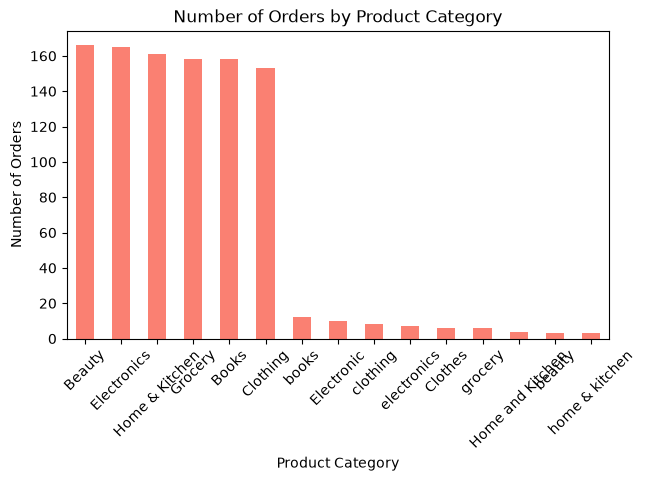

Category with the highest order volume: Beauty


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns 
# 1. Count total orders per category
order_counts = df['Product_Category'].value_counts()
print(order_counts)

# 2. Plot the bar chart
plt.figure(figsize=(7, 4))
order_counts.plot(kind="bar", color="salmon")
plt.title("Number of Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

# Find the winner
print(f"Category with the highest order volume: {order_counts.idxmax()}")


In [16]:
# 1. Total revenue per category
category_revenue = df.groupby("Product_Category")["Final_Amount"].sum()
print(category_revenue)

# 2. Check if highest orders match highest revenue
highest_order_cat = df["Product_Category"].value_counts().idxmax()
highest_rev_cat = category_revenue.idxmax()

print(f"Highest Orders: {highest_order_cat}")
print(f"Highest Revenue: {highest_rev_cat}")
print(f"Are they the same? {highest_order_cat == highest_rev_cat}")


Product_Category
Beauty              210137.3655
Books                40334.6945
Clothes               6899.0125
Clothing            361267.1305
Electronic            6464.2150
Electronics         194001.4615
Grocery              74131.4685
Home & Kitchen      152764.9175
Home and Kitchen      1890.8095
beauty                1002.0450
books                 3078.4075
clothing              5859.1415
electronics           6176.5170
grocery                556.9525
home & kitchen        1602.4790
Name: Final_Amount, dtype: float64
Highest Orders: Beauty
Highest Revenue: Clothing
Are they the same? False


In [17]:
# 1. Calculate both counts and revenue together
city_stats = df.groupby("City").agg(
    Total_Orders=("Customer_ID", "count"), Total_Revenue=("Final_Amount", "sum")
)
print(city_stats)

# 2. Find top cities
top_order_city = city_stats["Total_Orders"].idxmax()
top_revenue_city = city_stats["Total_Revenue"].idxmax()

print(f"Highest Order Volume City: {top_order_city}")
print(f"Highest Revenue City: {top_revenue_city}")
print(f"Are they the same? {top_order_city == top_revenue_city}")


           Total_Orders  Total_Revenue
City                                  
Ahmedabad            86     41020.9045
BANGALORE             6      2111.3795
Bengaluru            98    242748.8505
Chennai             111     61361.4800
Delhi                81     42569.3765
Delhi                 4     -1507.6320
Hyderabad           105     62745.3195
Jaipur               88    277321.3575
Jaipur                3      2258.2860
Kolkata              91    107172.7920
Mumbai              113     59029.6605
Mumbai                3       367.8930
PATNA                 2       644.9570
Patna                94     55163.6965
Pune                100     95652.0710
bengaluru             4      1061.8615
delhi                 4      2440.3050
jaipur                2       206.0100
mumbai                4      1022.8575
patna                 1       850.0000
Highest Order Volume City: Mumbai
Highest Revenue City: Jaipur
Are they the same? False


Delivery_Days
1.0     4.752830
2.0     4.707339
3.0     4.491875
4.0     4.427136
5.0     4.162500
6.0     4.044167
7.0     3.978788
8.0     3.880000
9.0     3.614286
10.0    4.000000
Name: Customer_Rating, dtype: float64


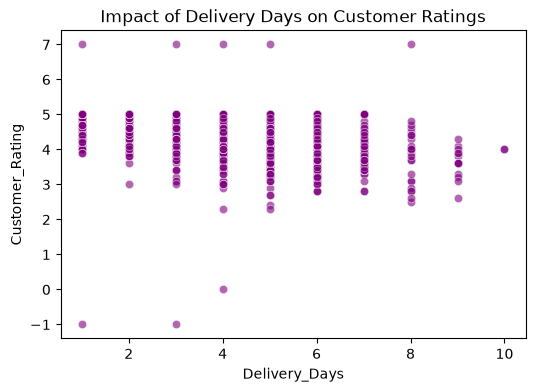

In [18]:
# 1. Grouped statistics: Average rating for each delivery day length
print(df.groupby("Delivery_Days")["Customer_Rating"].mean())

# 2. Visualization (Scatter plot or Box plot)
plt.figure(figsize=(6, 4))
sns.scatterplot(
    data=df, x="Delivery_Days", y="Customer_Rating", alpha=0.6, color="purple"
)
plt.title("Impact of Delivery Days on Customer Ratings")
plt.show()


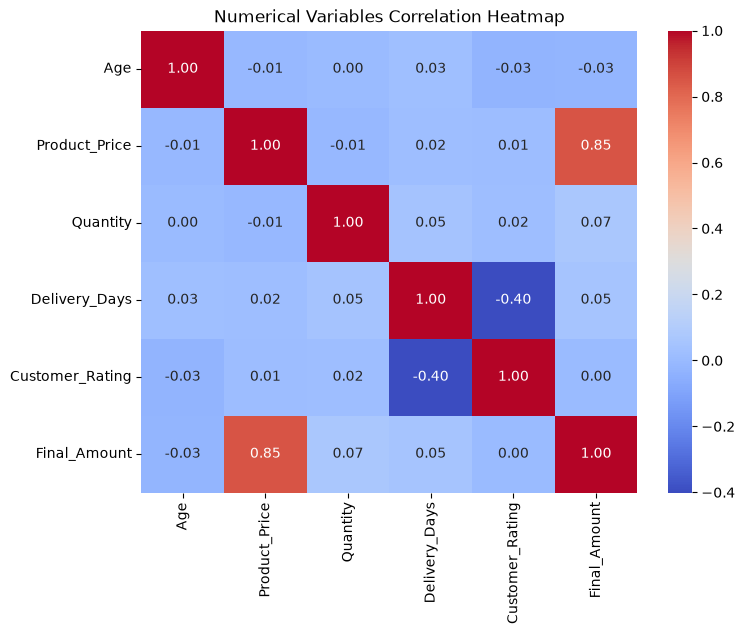

In [19]:
# 1. Select key numerical fields
numerical_features = [
    "Age",
    "Product_Price",
    "Quantity",
    "Delivery_Days",
    "Customer_Rating",
    "Final_Amount",
]
corr_matrix = df[numerical_features].corr()

# 2. Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Variables Correlation Heatmap")
plt.show()
